# 05 — Normal Equation vs Gradient Descent

**Session 05**

Gradient descent (GD) finds $\theta$ **iteratively**. For linear regression with squared error, there is also a **closed-form** solution called the **normal equation**. In this notebook we will:

1. Implement the normal equation.
2. Compare it with GD on the same data and loss.
3. Compare both with `sklearn.linear_model.LinearRegression`.
4. Benchmark the **cost** of each method.
5. Demonstrate when the normal equation **fails** (collinearity) and how to recover with `lstsq` / `pinv`.
6. Summarize **when to use which**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
np.random.seed(42)

## 1. The normal equation

For linear regression with squared error,

$$ J(\theta) = \frac{1}{2m}\,\|X\theta - y\|^2 $$

the optimum is where the gradient vanishes:

$$ \nabla J(\theta) = \frac{1}{m} X^{\top}(X\theta - y) = 0 $$

$$ \Rightarrow\; X^{\top} X\,\theta = X^{\top} y $$

$$ \boxed{\;\theta^{\star} = (X^{\top}X)^{-1}\,X^{\top} y\;} $$

**No learning rate, no iterations, no convergence worries.** Just linear algebra.

- $X$ has shape $m \times (n+1)$ (with the intercept column).
- $X^{\top}X$ has shape $(n+1) \times (n+1)$.
- Forming $X^{\top}X$ costs $O(m n^2)$; inverting it costs $O(n^3)$.

The normal equation is **exact** (up to floating-point error) — it lands precisely on the bottom of the bowl we saw in `04a`.

## 2. Load California Housing

Same data as `04a`. We will use **raw** (unstandardized) features for the normal equation — it is scale-invariant — but **standardized** features for GD.

We add a column of ones so the model has an intercept.

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing(as_frame=True)
df = housing.frame

X_raw = df.drop(columns="MedHouseVal").values
y_raw = df["MedHouseVal"].values.reshape(-1, 1)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

def add_intercept(X):
    return np.c_[np.ones((X.shape[0], 1)), X]

# raw (unstandardized) versions used by NE and sklearn
X_tr_raw = add_intercept(X_tr)
X_te_raw = add_intercept(X_te)

# standardized versions used by GD
scaler = StandardScaler().fit(X_tr)
X_tr_std = add_intercept(scaler.transform(X_tr))
X_te_std = add_intercept(scaler.transform(X_te))

print(f"train: X_tr_raw {X_tr_raw.shape}, X_tr_std {X_tr_std.shape}")
print(f"test : X_te_raw {X_te_raw.shape}, X_te_std {X_te_std.shape}")

train: X_tr_raw (16512, 9), X_tr_std (16512, 9)
test : X_te_raw (4128, 9), X_te_std (4128, 9)


## 3. Normal equation

We use `np.linalg.solve` rather than `np.linalg.inv`: solving $X^{\top}X\,\theta = X^{\top}y$ is slightly faster and numerically more stable than computing the inverse and then multiplying.

For linear regression with squared error:
$ J(\theta) = \frac{1}{2m}\,\| X\theta - y \|^2 $

Gradient:
$ \nabla_\theta J(\theta) = \frac{1}{m}\,X^\top (X\theta - y) $

In [3]:
def J(theta, X, y):
    r = X @ theta - y
    return 0.5 * np.sum(r ** 2) / len(y)

def grad(theta, X, y):
    r = X @ theta - y
    return X.T @ r / len(y)

# def normal_equation(X, y):
#     X_inv = np.linalg.inv(X.T @ X)
#     return X_inv @ X.T @ y
# # (X.T @ X)^-1 @ X.T y

def normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

def gd(X, y, theta_init, lr=0.1, n_iter=500):
    theta = theta_init.copy().astype(float)
    losses = [J(theta, X, y)]
    for _ in range(n_iter):
        theta = theta - lr * grad(theta, X, y)
        losses.append(J(theta, X, y))
    return theta, np.array(losses)

In [4]:
theta_ne = normal_equation(X_tr_raw, y_tr)

train_loss_ne = J(theta_ne, X_tr_raw, y_tr)
test_loss_ne  = J(theta_ne, X_te_raw, y_te)

print("theta (normal equation):")
print(theta_ne.reshape(-1))
print(f"\ntrain loss : {train_loss_ne}")
print(f"test  loss : {test_loss_ne}")
print(f"test  RMSE : {np.sqrt(2 * test_loss_ne)}")

theta (normal equation):
[-3.70232777e+01  4.48674910e-01  9.72425752e-03 -1.23323343e-01
  7.83144907e-01 -2.02962058e-06 -3.52631849e-03 -4.19792487e-01
 -4.33708065e-01]

train loss : 0.25896656276233493
test  loss : 0.2779457993476248
test  RMSE : 0.7455813830127799


## 4. Gradient descent on the same data

Same `gd()` as `04`. We run it on **standardized** features with a reasonable learning rate.

Because the normal equation and GD optimize the **same objective**, their coefficients should agree (up to convergence tolerance) when GD runs on standardized features — because the loss and its minimizer are unchanged by an invertible linear transformation of the features.

In [5]:
theta_init = np.zeros((X_tr_std.shape[1], 1))

t0 = time.perf_counter()
theta_gd, losses_gd = gd(X_tr_std, y_tr, theta_init, lr=0.1, n_iter=800)
t_gd_total = time.perf_counter() - t0

train_loss_gd = J(theta_gd, X_tr_std, y_tr)
test_loss_gd  = J(theta_gd, X_te_std, y_te)

print(f"GD training time: {t_gd_total:.3f} s")
print(f"train loss: {train_loss_gd:.6f}")
print(f"test  loss: {test_loss_gd:.6f}")
print(f"test  RMSE: {np.sqrt(2 * test_loss_gd):.6f}")

GD training time: 0.610 s
train loss: 0.258970
test  loss: 0.278061
test  RMSE: 0.745736


## 5. Side-by-side comparison

The two methods reach the **same minimum** of $J$. The normal equation gets there in **one step** and is exact; GD gets there in **many steps** but each step is cheap.

In [6]:
# align coefficients: GD was trained on standardized features, so undo the scaling
# to compare intercept/coefficients on the raw feature scale.
mu    = scaler.mean_
sigma = scaler.scale_

# h_std(X) = theta_std[0] + sum_j theta_std[j+1] * (x_j - mu_j) / sigma_j
#         = [theta_std[0] - sum_j theta_std[j+1]*mu_j/sigma_j] + sum_j (theta_std[j+1]/sigma_j) * x_j
theta_gd_raw = np.empty_like(theta_gd)
theta_gd_raw[0, 0] = theta_gd[0, 0] - np.sum(theta_gd[1:, 0] * mu / sigma)
theta_gd_raw[1:, 0] = theta_gd[1:, 0] / sigma

names = ["intercept"] + df.drop(columns="MedHouseVal").columns.tolist()
print(f"{'feature':12s} {'normal_eq':>14s} {'gd (raw-scale)':>16s} {'diff':>12s}")
for n, a, b in zip(names, theta_ne.ravel(), theta_gd_raw.ravel()):
    print(f"{n:12s} {a:14.6f} {b:16.6f} {abs(a-b):12.2e}")

feature           normal_eq   gd (raw-scale)         diff
intercept        -37.023278       -36.727679     2.96e-01
MedInc             0.448675         0.450017     1.34e-03
HouseAge           0.009724         0.009780     5.61e-05
AveRooms          -0.123323        -0.125108     1.78e-03
AveBedrms          0.783145         0.790736     7.59e-03
Population        -0.000002        -0.000002     1.98e-07
AveOccup          -0.003526        -0.003538     1.13e-05
Latitude          -0.419792        -0.416325     3.47e-03
Longitude         -0.433708        -0.430155     3.55e-03


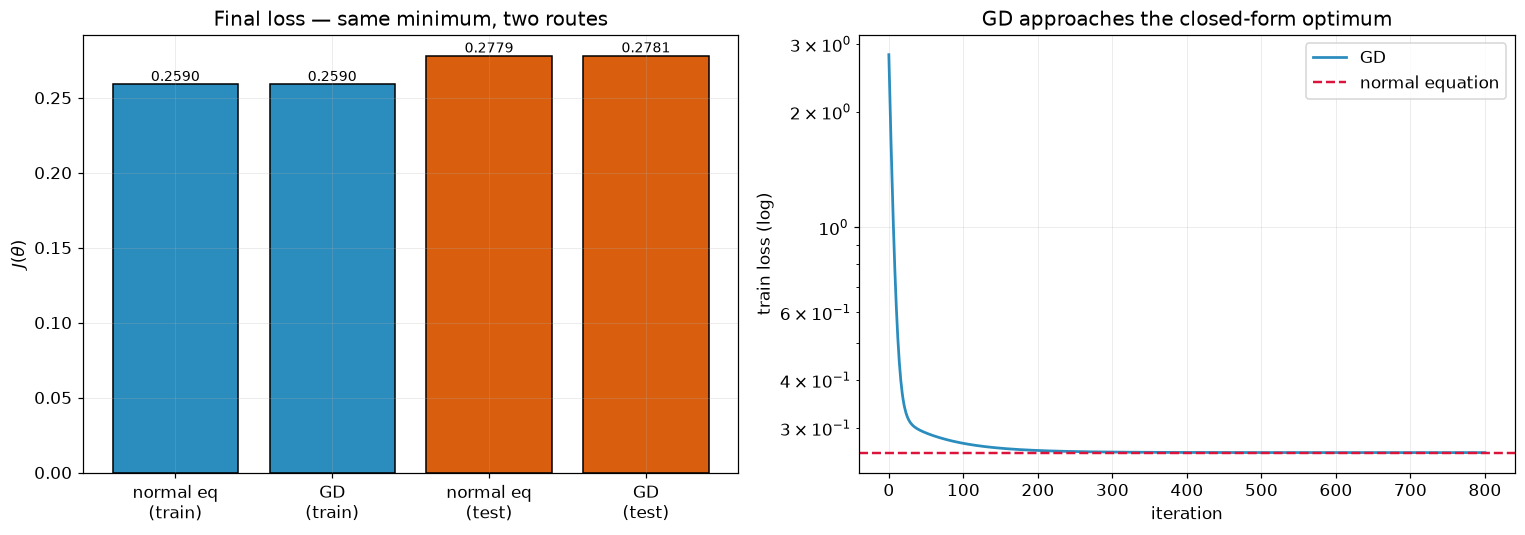

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- loss comparison
bars = ax1.bar(
    ["normal eq\n(train)", "GD\n(train)", "normal eq\n(test)", "GD\n(test)"],
    [train_loss_ne, train_loss_gd, test_loss_ne, test_loss_gd],
    color=["#2b8cbe", "#2b8cbe", "#d95f0e", "#d95f0e"],
    edgecolor="k",
)
ax1.set_ylabel("$J(\\theta)$")
ax1.set_title("Final loss — same minimum, two routes")
for b, v in zip(bars, [train_loss_ne, train_loss_gd, test_loss_ne, test_loss_gd]):
    ax1.text(b.get_x() + b.get_width()/2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)

# --- convergence curves on the training set
ax2.plot(losses_gd, color="#2b8cbe", linewidth=1.8, label="GD")
ax2.axhline(train_loss_ne, color="crimson", linestyle="--", linewidth=1.6, label="normal equation")
ax2.set_yscale("log")
ax2.set_xlabel("iteration")
ax2.set_ylabel("train loss (log)")
ax2.set_title("GD approaches the closed-form optimum")
ax2.legend()

plt.tight_layout()
plt.show()

## 6. Comparison with scikit-learn

`LinearRegression` internally uses SVD (via `scipy.linalg.lstsq`), not explicit inversion. This is *more numerically stable* than the normal equation while producing the same coefficients.

We use `fit_intercept=False` because our $X$ already has the intercept column.

In [8]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression(fit_intercept=False)
lr_model.fit(X_tr_raw, y_tr.ravel())
theta_sk = lr_model.coef_.reshape(-1, 1)

print(f"{'feature':12s} {'normal_eq':>14s} {'sklearn':>14s} {'diff':>12s}")
for n, a, b in zip(names, theta_ne.ravel(), theta_sk.ravel()):
    print(f"{n:12s} {a:14.6f} {b:14.6f} {abs(a-b):12.2e}")

train_loss_sk = J(theta_sk, X_tr_raw, y_tr)
test_loss_sk  = J(theta_sk, X_te_raw, y_te)
print(f"\ntrain loss (sklearn): {train_loss_sk:.6f}")
print(f"test  loss (sklearn): {test_loss_sk:.6f}")

feature           normal_eq        sklearn         diff
intercept        -37.023278     -37.023278     4.40e-10
MedInc             0.448675       0.448675     1.11e-12
HouseAge           0.009724       0.009724     7.71e-14
AveRooms          -0.123323      -0.123323     1.15e-12
AveBedrms          0.783145       0.783145     3.64e-12
Population        -0.000002      -0.000002     2.47e-16
AveOccup          -0.003526      -0.003526     1.29e-14
Latitude          -0.419792      -0.419792     4.71e-12
Longitude         -0.433708      -0.433708     5.12e-12

train loss (sklearn): 0.258967
test  loss (sklearn): 0.277946


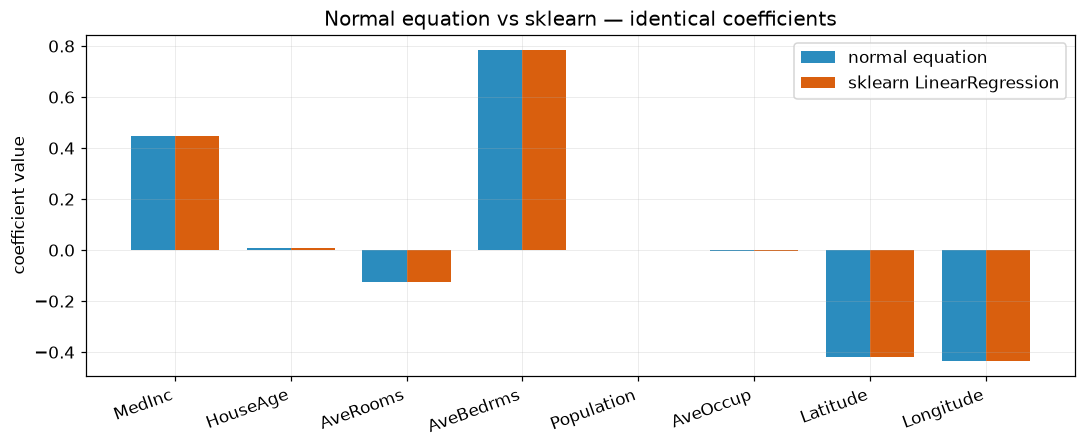

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
xpos = np.arange(len(names)-1)
width = 0.38

ax.bar(xpos - width/2, theta_ne.ravel()[1:], width, label="normal equation", color="#2b8cbe")
ax.bar(xpos + width/2, theta_sk.ravel()[1:], width, label="sklearn LinearRegression", color="#d95f0e")
ax.set_xticks(xpos)
ax.set_xticklabels(names[1:], rotation=20, ha="right")
ax.set_ylabel("coefficient value")
ax.set_title("Normal equation vs sklearn — identical coefficients")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Cost: how expensive is each method?

Cost per full solve / per iteration:

- **Normal equation:** $O(m n^2 + n^3)$ in **one shot**.
- **Gradient descent:** $O(m n)$ **per iteration**, times many iterations.

Let's measure on the actual dataset, then scale it up synthetically in the next section.

In [10]:
def time_normal_eq(X, y, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        _ = np.linalg.solve(X.T @ X, X.T @ y)
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def time_gd_iters(X, y, n_iter=200, lr=0.1):
    theta = np.zeros((X.shape[1], 1))
    t0 = time.perf_counter()
    for _ in range(n_iter):
        theta = theta - lr * grad(theta, X, y)
    return time.perf_counter() - t0

t_ne   = time_normal_eq(X_tr_raw, y_tr)
t_gd   = time_gd_iters(X_tr_std, y_tr, n_iter=200)

print(f"normal equation : {t_ne*1000:8.2f} ms   (one solve)")
print(f"GD              : {t_gd*1000:8.2f} ms   (200 iters)")
print(f"GD per iteration: {t_gd/200*1000:8.3f} ms")

normal equation :     1.18 ms   (one solve)
GD              :   117.71 ms   (200 iters)
GD per iteration:    0.589 ms


## 8. When the normal equation fails — collinearity

If $X^{\top}X$ is **singular**, the normal equation has **no unique solution**. Common causes:

- A feature is a **linear combination** of others (perfect collinearity).
- $m < n+1$ (fewer samples than features).
- A column is **constant** (other than the intercept).

Below we deliberately **duplicate** a column. `np.linalg.solve` will fail, but `np.linalg.lstsq` (which uses SVD, like `sklearn`) recovers a **minimum-norm** solution that achieves the same predictions.

In [16]:
# duplicate the first feature
X_dup = np.c_[X_tr_raw, X_tr[:, 0]]                 # shape: (m, n+2)
print("condition number of X^T X:", np.linalg.cond(X_dup.T @ X_dup))

print("\n--- np.linalg.solve (normal equation) ---")
try:
    theta_dup_solve = np.linalg.solve(X_dup.T @ X_dup, X_dup.T @ y_tr)
    print("solve succeeded but result is unreliable:")
    print(theta_dup_solve.ravel())
except np.linalg.LinAlgError as e:
    print(f"solve failed: {e}")

print("\n--- np.linalg.lstsq (SVD-based, like sklearn) ---")
theta_dup_lstsq, *_ = np.linalg.lstsq(X_dup, y_tr, rcond=None)
print(theta_dup_lstsq.ravel())

# both models must predict identically on the training data
pred_solve = X_dup @ theta_dup_solve if 'theta_dup_solve' in locals() else None
pred_lstsq = X_dup @ theta_dup_lstsq
print(f"\nlstsq train loss : {J(theta_dup_lstsq, X_dup, y_tr):.6f}")
print(f"original train loss (full-rank model): {train_loss_ne:.6f}")

condition number of X^T X: 1.6221202418668272e+19

--- np.linalg.solve (normal equation) ---
solve failed: Singular matrix

--- np.linalg.lstsq (SVD-based, like sklearn) ---
[-3.70232777e+01  2.24337455e-01  9.72425752e-03 -1.23323343e-01
  7.83144907e-01 -2.02962058e-06 -3.52631849e-03 -4.19792487e-01
 -4.33708065e-01  2.24337455e-01]

lstsq train loss : 0.258967
original train loss (full-rank model): 0.258967


## 9. Scalability — how each method scales

Same data, but larger $n$: how do the two methods respond?

- Normal equation cost **grows fast** with $n$ because of the $n^3$ inversion.
- GD's cost **per iteration** is linear in $n$; the iteration count may grow but not the per-step cost.

The synthetic benchmark below makes the tradeoff concrete.

In [12]:
def bench(m, n, n_gd_iters=200):
    np.random.seed(0)
    X = np.random.randn(m, n + 1)
    X[:, 0] = 1.0
    y = np.random.randn(m, 1)

    t_ne = time_normal_eq(X, y, reps=3)

    theta = np.zeros((n + 1, 1))
    t0 = time.perf_counter()
    for _ in range(n_gd_iters):
        theta = theta - 0.01 * grad(theta, X, y)
    t_gd = time.perf_counter() - t0

    return t_ne, t_gd / n_gd_iters, t_gd

print(f"{'m':>6s} {'n':>6s} {'NE (s)':>10s} {'GD/iter (ms)':>14s} {'GD total (s)':>13s}")
for m, n in [(5000, 10), (5000, 100), (5000, 500), (5000, 2000)]:
    t_ne, t_gd_per, t_gd_total = bench(m, n)
    print(f"{m:6d} {n:6d} {t_ne:10.4f} {t_gd_per*1000:14.3f} {t_gd_total:13.4f}")

     m      n     NE (s)   GD/iter (ms)  GD total (s)
  5000     10     0.0005          0.151        0.0301
  5000    100     0.0781          0.829        0.1659
  5000    500     0.2792          2.790        0.5580
  5000   2000     0.9093          6.177        1.2355


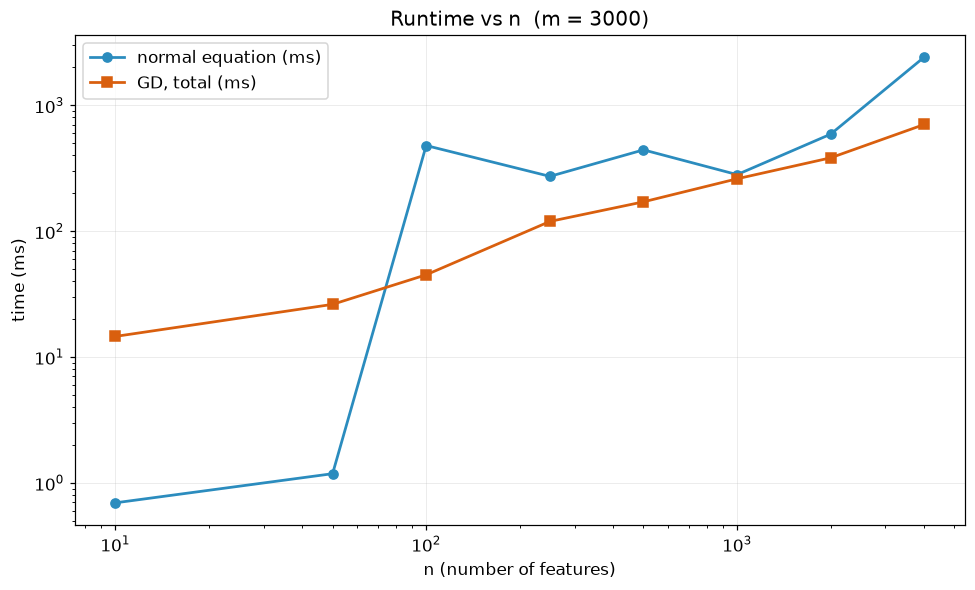

Rule of thumb: for large n, GD wins per unit of work; for small n, the normal equation wins outright.


In [14]:
# visual: growth of NE cost vs n
ns = [10, 50, 100, 250, 500, 1000, 2000, 4000]
# ns = [10, 50, 100, 250, 500]
m = 3000
ne_times = []
gd_times = []
for n in ns:
    t_ne, _, t_gd_total = bench(m, n, n_gd_iters=100)
    ne_times.append(t_ne)
    gd_times.append(t_gd_total)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(ns, np.array(ne_times) * 1000, "o-", color="#2b8cbe", linewidth=1.8, label="normal equation (ms)")
ax.plot(ns, np.array(gd_times) * 1000, "s-", color="#d95f0e", linewidth=1.8, label="GD, total (ms)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("n (number of features)")
ax.set_ylabel("time (ms)")
ax.set_title(f"Runtime vs n  (m = {m})")
ax.legend()
plt.tight_layout()
plt.show()

print("Rule of thumb: for large n, GD wins per unit of work; "
      "for small n, the normal equation wins outright.")

## 10. When to use which

| Situation | Prefer |
|---|---|
| Small to medium $n$, exact solution wanted | **Normal equation** (or `lstsq` / `LinearRegression`) |
| $n$ large (thousands to millions) | **GD** / **SGD** / **mini-batch** |
| $X^{\top}X$ singular or ill-conditioned | **`lstsq` / ridge regression** (not plain inversion) |
| Streaming or out-of-memory data | **SGD / mini-batch GD** |
| Wanted: interpretable, single-shot fit | **Normal equation** |
| Wanted: extend easily to non-quadratic losses | **GD** (the pattern generalizes) |

The normal equation is the **cleanest baseline** for linear regression; GD is the **pattern that scales** to everything else in machine learning.

## 11. Summary

- **Normal equation:** $\theta^{\star} = (X^{\top}X)^{-1} X^{\top} y$. One shot, exact, no learning rate.
- Cost: $O(m n^2 + n^3)$ — cheap when $n$ is modest, expensive when $n$ is large.
- Requires $X^{\top}X$ invertible; **fails** under collinearity, and behaves badly near it.
- **`lstsq` / `pinv` / SVD** is the numerically robust alternative — that's what `sklearn` uses under the hood.
- **Gradient descent** approaches the same minimum iteratively at $O(m n)$ per step — its power shows up when $n$ is large or when the loss is not quadratic.

**Next session (06):** classification — where the output is discrete, MSE + sigmoid is not convex, and cross-entropy takes over.